In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Этап-1. Очистка данных

In [2]:
df = pd.read_csv('amazon.csv')
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

In [4]:
df['discounted_price'] = df['discounted_price'].astype(str).str.replace('₹', '').str.replace(',', '')
df['actual_price'] = df['actual_price'].astype(str).str.replace('₹', '').str.replace(',', '')

df['discounted_price'] = pd.to_numeric(df['discounted_price'], errors='coerce')
df['actual_price'] = pd.to_numeric(df['actual_price'], errors='coerce')

df['discount_percentage'] = df['discount_percentage'].astype(str).str.replace('%', '')
df['discount_percentage'] = pd.to_numeric(df['discount_percentage'], errors='coerce') / 100

df['rating'] = df['rating'].astype(str).str.replace(r'[^0-9.]', '', regex=True)
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['rating'] = df['rating'].fillna(df['rating'].median())

df['rating_count'] = df['rating_count'].astype(str).str.replace(',', '')
df['rating_count'] = pd.to_numeric(df['rating_count'], errors='coerce')
df['rating_count'] = df['rating_count'].fillna(df['rating_count'].median())
df['rating_count'] = df['rating_count'].astype('int64')

In [5]:
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,0.64,4.2,24269,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,0.43,4.0,43994,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,0.90,3.9,7928,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,0.53,4.2,94363,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,0.61,4.2,16905,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1465 non-null   object 
 1   product_name         1465 non-null   object 
 2   category             1465 non-null   object 
 3   discounted_price     1465 non-null   float64
 4   actual_price         1465 non-null   float64
 5   discount_percentage  1465 non-null   float64
 6   rating               1465 non-null   float64
 7   rating_count         1465 non-null   int64  
 8   about_product        1465 non-null   object 
 9   user_id              1465 non-null   object 
 10  user_name            1465 non-null   object 
 11  review_id            1465 non-null   object 
 12  review_title         1465 non-null   object 
 13  review_content       1465 non-null   object 
 14  img_link             1465 non-null   object 
 15  product_link         1465 non-null   o

In [7]:
df = df.drop(columns=['about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link'], axis=1)
df.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,0.64,4.2,24269
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,0.43,4.0,43994
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,0.90,3.9,7928
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,0.53,4.2,94363
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,0.61,4.2,16905


# Этап-2. EDA

## 2.1. Анализ взаимосвязей метрик (Корреляционный анализ)

In [8]:
df.corr(numeric_only=True)

,discounted_price,actual_price,discount_percentage,rating,rating_count
discounted_price,1.000000,0.961915,-0.242412,0.120335,-0.027081
actual_price,0.961915,1.000000,-0.118098,0.121636,-0.035959
discount_percentage,-0.242412,-0.118098,1.000000,-0.155273,0.011097
rating,0.120335,0.121636,-0.155273,1.000000,0.101526
rating_count,-0.027081,-0.035959,0.011097,0.101526,1.000000


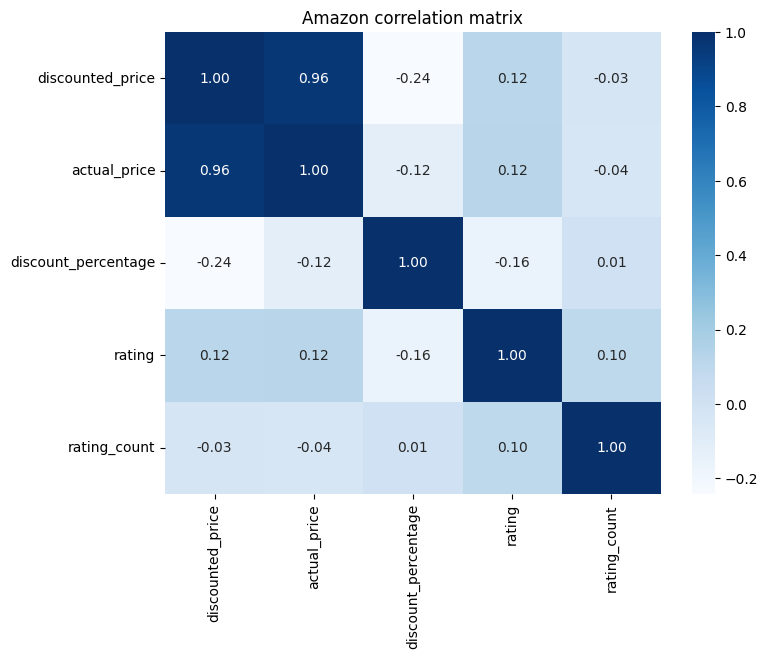

In [9]:
plt.figure(figsize=(8, 6))
plt.title('Amazon correlation matrix')
sns.heatmap(data=df.corr(numeric_only=True), cmap='Blues', annot=True, fmt='.2f')
plt.show()

### Выводы по корреляционной матрице:
* **Сильная связь:** `actual_price` и `discounted_price` имеют корреляцию 0.96, что вполне естественно.
* **Скидки и рейтинг:** Обнаружена небольшая отрицательная корреляция (-0.16) между процентом скидки и рейтингом. Это может указывать на то, что высокие скидки чаще устанавливаются на товары с меньшим спросом или низкими оценками.
* **Цена и размер скидки:** Отрицательная корреляция (-0.24) между ценой со скидкой и процентом скидки показывает, что на более дорогие товары редко дают огромные скидки в процентах.

## 2.2. Инженерия признаков (Feature Engineering)

In [10]:
df['sub_category'] = df['category'].str.split('|').str[2]
top10_subcat = df['sub_category'].value_counts().head(10).index.tolist()
top10_subcat

['Cables&Accessories',
 'SmallKitchenAppliances',
 'Accessories',
 'MobileAccessories',
 'Vacuum,Cleaning&Ironing',
 'Smartphones&BasicMobiles',
 'SmartWatches',
 'Televisions',
 'Headphones',
 'Keyboards,Mice&InputDevices']

In [11]:
df_top10 = df[df['sub_category'].isin(top10_subcat)].copy()
df_top10.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,sub_category
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,0.64,4.2,24269,Cables&Accessories
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,0.43,4.0,43994,Cables&Accessories
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,0.90,3.9,7928,Cables&Accessories
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,0.53,4.2,94363,Cables&Accessories
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,0.61,4.2,16905,Cables&Accessories


Из исходной строки категорий выделен 3-й уровень иерархии (`sub_category`). Для сохранения статистической значимости сформирован датасет `df_top10`, включающий только ключевые подкатегории. Мелкие категории исключены из дальнейшего анализа во избежание искажений из-за малого размера выборки.

## 2.3. Анализ факторов популярности по подкатегориям.

In [12]:
df_top10.groupby('sub_category', as_index=False)[['discounted_price', 'discount_percentage', 'rating', 'rating_count']].median().sort_values(by='rating_count', ascending=False)

,sub_category,discounted_price,discount_percentage,rating,rating_count
2,Headphones,894.0,0.625,3.95,50584.5
7,Smartphones&BasicMobiles,12999.0,0.240,4.10,18998.0
6,SmartWatches,1999.0,0.745,4.10,17832.0
3,"Keyboards,Mice&InputDevices",484.0,0.485,4.20,7279.0
1,Cables&Accessories,299.0,0.620,4.20,6255.0
4,MobileAccessories,436.5,0.650,4.20,6181.0
8,Televisions,19999.0,0.400,4.20,4703.0
5,SmallKitchenAppliances,1290.0,0.430,4.10,2518.0
9,"Vacuum,Cleaning&Ironing",1024.0,0.400,4.10,2125.0
0,Accessories,349.0,0.590,4.00,1079.0


**Инсайт по подкатегориям**: Категория `Headphones` является абсолютным лидером по медианному числу отзывов (~50.5k), несмотря на наименьший медианный рейтинг (3.95). Это указывает на то, что в массовых дешевых аксессуарах фактор цены и скидки (62.5%) драйвит продажи сильнее, чем идеальный рейтинг товара.

## 2.4. Проверка нелинейных связей (Рейтинг и Скидки vs Популярность)

In [13]:
df_top10['rating_group'] = pd.cut(df_top10['rating'], bins=[0, 3.5, 4.0, 4.3, 5.0])
df_top10.groupby('rating_group', observed=False)['rating_count'].median() 

rating_group
(0.0, 3.5]     791.5
(3.5, 4.0]    3453.5
(4.0, 4.3]    7298.0
(4.3, 5.0]    5179.0
Name: rating_count, dtype: float64

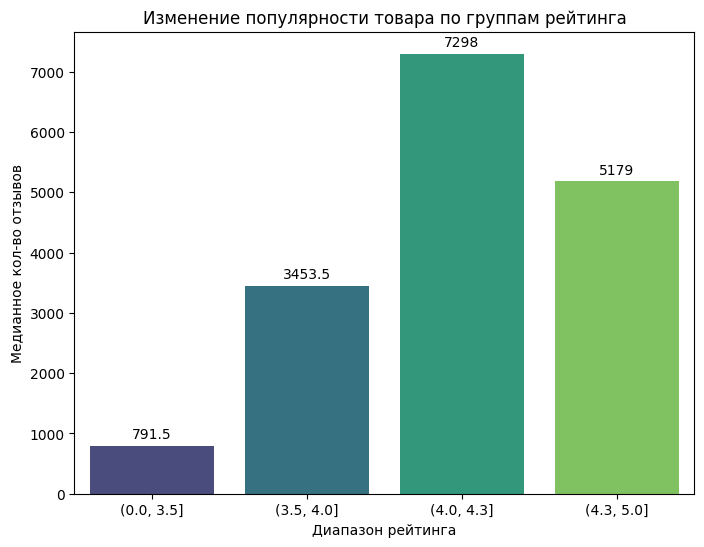

In [14]:
plt.figure(figsize=(8,6))
ax = sns.barplot(
    data=df_top10.groupby('rating_group', observed=False, as_index=False)['rating_count'].median(), 
    x='rating_group', 
    y='rating_count', 
    hue='rating_group',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Изменение популярности товара по группам рейтинга')
plt.xlabel('Диапазон рейтинга')
plt.ylabel('Медианное кол-во отзывов')
plt.show()

**Вывод по рейтингу**
* Популярность товара (`rating_count`) демонстрирует взрывной рост при пересечении отметки рейтинга 3.5 (медиана увеличивается в 5 раз — с 651 до 3 453 отзывов). Пик продаж приходится на диапазон 4.0–4.3 (медиана 7 458), после чего активность покупателей снижается.

In [15]:
df_top10['discount_group'] = pd.cut(df_top10['discount_percentage'], bins=[0, 0.3, 0.5, 0.7, 1.0])
df_top10.groupby('discount_group', observed=False)['rating_count'].median()

discount_group
(0.0, 0.3]    11029.0
(0.3, 0.5]     4859.0
(0.5, 0.7]     3578.0
(0.7, 1.0]     4415.0
Name: rating_count, dtype: float64

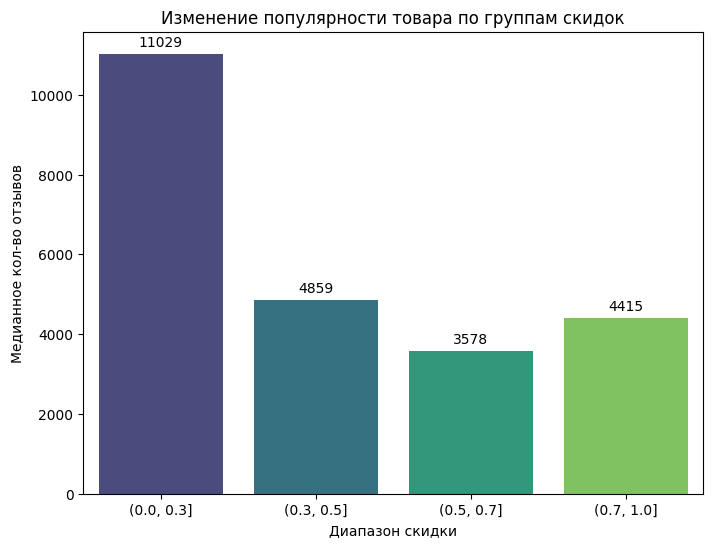

In [16]:
plt.figure(figsize=(8,6))
ax = sns.barplot(
    data=df_top10.groupby('discount_group', observed=False, as_index=False)['rating_count'].median(),
    x='discount_group',
    y='rating_count',
    hue='discount_group',
    palette='viridis',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Изменение популярности товара по группам скидок')
plt.xlabel('Диапазон скидки')
plt.ylabel('Медианное кол-во отзывов')
plt.show()

**Вывод по скидкам**
* Товары с минимальной скидкой ($<30\%$) являются абсолютными лидерами по числу отзывов (медиана 11 029). Это объясняется тем, что сильные бренды и ликвиды генерируют органический спрос без необходимости глубокого уценивания, в то время как высокие скидки ($>50\%$) применяются вынужденно для привлечения внимания к менее известным или нишевым позициям. 

# 3. Бизнес-рекомендации и итоговые выводы

По результатам EDA выявлены 3 ключевые закономерности, характерные для поведения покупателей и селлеров на площадке:

1. **Категория `Headphones` — объем продаж держится на массовом спросе, а не на идеальном рейтинге**
   Категория лидирует по числу отзывов (медиана ~50.5k), но имеет наименьший медианный рейтинг (3.95). Для дешевой электроники и аксессуаров оценка около 3.9–4.0 является нормой из-за высокого потока естественных негативных отзывов (брак кабелей, аккумуляторы). 
   * **Вывод для селлеров:** Не стоит отказываться от ниши из-за высокого уровня негативных отзывов — высокий объем спроса полностью перекрывает этот риск при правильной экономике единицы товара (Unit-экономике).

2. **Агрессивные скидки (>30%) не приводят к росту популярности карточки**
   Наибольшее число отзывов концентрируется у товаров с умеренной скидкой до 30% (медиана ~11k). Карточки со скидками 50–70% застревают на уровне 3.5–4k отзывов.
   * **Вывод для селлеров:** Популярные товары и так имеют органический спрос, им не нужна глубокая уценка. Установка скидок свыше 50% не сделает карточку бестселлером, а только порежет маржу, так как покупатели часто воспринимают критический дисконт как признак некачественного товара.

3. **«Золотая зона» рейтинга — от 4.0 до 4.3**
   До рейтинга 3.5 карточка практически не получает трафика и отзывов (медиана ~650). Начиная с 3.5 наблюдается резкий скачок внимания покупателей, а пик популярности приходится на диапазон 4.0–4.3 (медиана 7.4k). 
   * **Вывод для селлеров:** Главная задача при продвижении карточки — как можно быстрее вывести рейтинг в зону 4.0+. При проседании рейтинга ниже 3.8 карточка рискует быстро терять позиции и уйти в «слепую зону» (ниже 3.5), откуда выходить экономически нецелесообразно.